# 第 2 课｜招聘结构与可视化分析

**90 分钟：指标口径 15′ → 分组聚合 25′ → 图表实践 35′ → 结论表达 15′**

目标：用公司、招聘类型和城市三个维度回答样本结构问题；每张图附“数字证据＋边界”。
不做薪资排行：缺失覆盖率和币种口径尚不足。不开场就画时间趋势：当前快照不是历史存量序列。

> **增强版阅读方法**：先看本节问题，预测输出，再运行代码，最后解释数字。
> 关键代码已加中文注释，说明“为什么做、参数是什么、结果的行列单位是什么”。
> 标有【主线】的段落用于课堂；【拓展】用于教师演示或课后，不要求90分钟内完成所有扩展。
> 长代码按完整步骤拆成较短单元；每本仍需从上到下依次运行。

In [1]:
# Path把文件路径当作对象处理；用 / 拼接路径可兼容不同操作系统。
from pathlib import Path
import sys, json, re
# NumPy处理数组和数值；np只是约定俗成的简称，不是Python关键字。
import numpy as np
# Pandas处理带行列标签的表格；Series是一列，DataFrame是一张表。
import pandas as pd
# display显示表格，Markdown把动态生成的结论渲染成Notebook文字。
from IPython.display import display, Markdown

# 支持从项目根目录、课程目录或 notebooks 目录启动。
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'course_utils.py').exists()), None)
if ROOT is None:
    ROOT = next((p / 'data_analysis202612' for p in candidates
                 if (p / 'data_analysis202612' / 'course_utils.py').exists()), None)
assert ROOT is not None, '请从项目根目录或课程目录启动 Jupyter'
# 将课程目录加入模块搜索路径，才能导入同目录的course_utils.py。
sys.path.insert(0, str(ROOT))
# 教学工具只封装路径、清洗和绘图；SKILLS是词典，KEY是复合身份字段，SEED固定随机种子。
from course_utils import *
# 以下设置只影响屏幕展示，不删数据、不改变统计结果；完整结果仍会导出。
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_colwidth', 65)
pd.set_option('display.max_rows', 20)
print('课程目录：', ROOT)
print('Python：', sys.version.split()[0])
print('解释器：', sys.executable)

课程目录： /Users/luosen/WorkBuddy/JobsCrawler/data_analysis202612
Python： 3.10.16
解释器： /Users/luosen/WorkBuddy/JobsCrawler/data_analysis202612/.venv/bin/python


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
setup_plotting()
path = DATA / 'processed' / 'jobs_clean.parquet'
assert path.exists(), '请先运行第1课'
# 本课读取上一课已清洗的固定快照结果，而不是重新抓取官网。
jobs = pd.read_parquet(path)
# 文件中的复杂列是JSON文本；先解码为列表，explode才会按城市展开而不是保留整段字符串。
jobs['cities'] = jobs['cities'].map(json.loads)
# N是全量职位分母；如果之后筛选子集，必须显式更换分母，不能继续沿用全量N。
N = len(jobs)
print(f'固定快照：{N:,} 条职位，{jobs.source.nunique()} 家公司')

固定快照：40,661 条职位，16 家公司


## 1. 指标先于图表

| 指标 | 公式与分母 |
|---|---|
| 公司职位数 | 该来源不同 `job_key` 的数量 |
| 公司样本占比 | 公司职位数 / 全部职位数 |
| 公司内招聘类型占比 | 公司某类型职位数 / 该公司全部职位数 |
| 城市岗位覆盖数 | 包含该城市的不同职位数 |
| 城市覆盖率 | 城市岗位覆盖数 / 全部职位数 |

一条职位可覆盖北京和上海，因此城市覆盖数之和可能超过职位总数，城市覆盖率也不要求合计100%。
同一职位跨城市展开后，在同一个城市只计一次。省份、范围标签和待核验地点不进入城市图。

,source,company_name,jobs,share
3,bytedance,字节跳动,17053,0.419395
0,alibaba,阿里巴巴,4744,0.116672
9,meituan,美团,3221,0.079216
8,kuaishou,快手,2563,0.063033
14,tencent,腾讯,2259,0.055557
7,jd,京东,2025,0.049802
5,didi,滴滴,1808,0.044465
15,xiaohongshu,小红书,1299,0.031947
1,baidu,百度,1058,0.026020
10,mihoyo,米哈游,946,0.023266


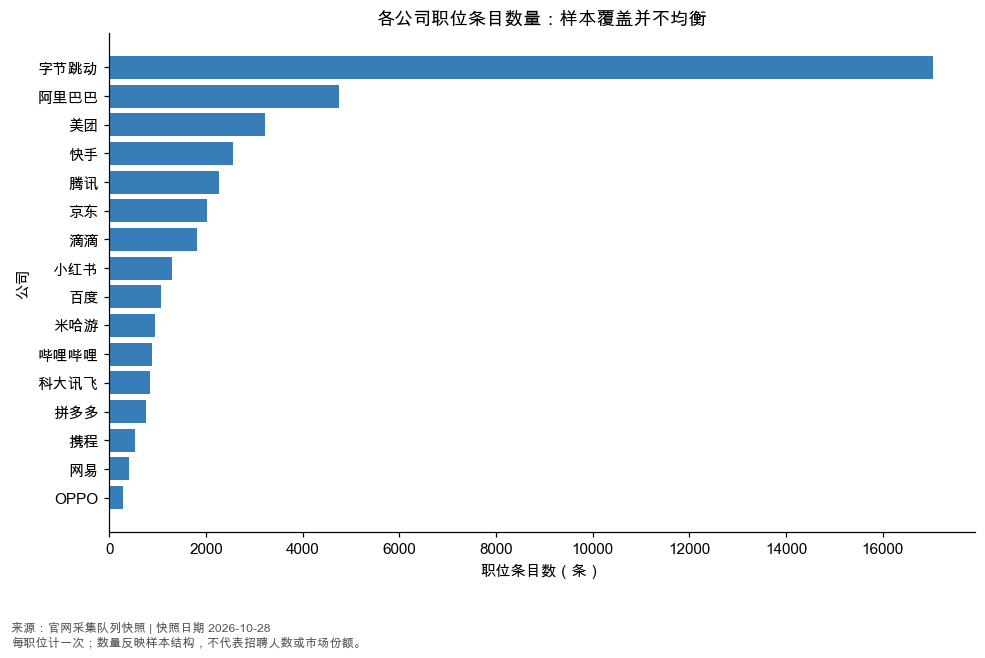

In [3]:
# 按来源和显示名分组；as_index=False让分组键保留为普通列，便于绘图与导出。
company_counts = (jobs.groupby(['source', 'company_name'], as_index=False)
                  .agg(jobs=('job_key', 'nunique')).sort_values('jobs', ascending=False))
# 比例=该公司职位数/全部职位数；这是样本构成，不是市场占有率。
company_counts['share'] = company_counts['jobs'] / N
display(company_counts)
# fig是整张图，ax是绘图区；figsize以英寸指定画布大小，后续save_figure统一添加来源注记。
fig, ax = plt.subplots(figsize=(9, 6))
# 横向条形图从下往上画；反转排序使最大值出现在上方，不改变原始底稿。
data = company_counts.iloc[::-1]
# barh绘制横向条形图；类别标签较长时比竖向柱更易读，长度编码职位条数。
ax.barh(data['company_name'], data['jobs'], color='#377eb8')
ax.set(title='各公司职位条目数量：样本覆盖并不均衡', xlabel='职位条目数（条）', ylabel='公司')
save_figure(fig, '02_company_counts', '每职位计一次；数量反映样本结构，不代表招聘人数或市场份额。')
# 每张图保留数值底稿，学生可用同一张表复算占比、核对文字结论。
csv_export(company_counts, '02_company_counts')

## 2. 公司内比较：数量和占比回答不同问题

使用 `recruitment_type` 的统一编码，不使用格式不一致的 `portal`。
这里把应届、科研实习等保留为独立类型，避免“校招一定等于全职”的混淆。

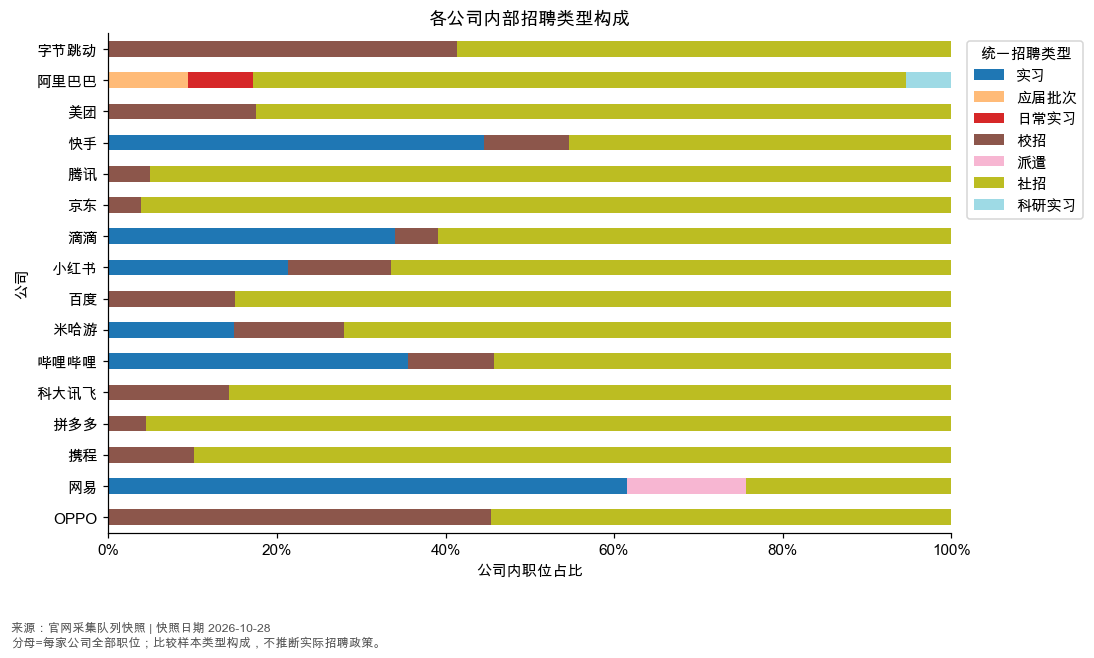

In [4]:
type_names = {'society': '社招', 'campus': '校招', 'graduate': '应届批次',
              'internship': '实习', 'regular_intern': '日常实习', 'research_intern': '科研实习', 'dispatch': '派遣'}
jobs['recruitment_group'] = jobs['recruitment_type'].map(type_names).fillna('未分类')
# 交叉表每个单元格是“某公司×某招聘类型”的职位数。
type_table = pd.crosstab(jobs['company_name'], jobs['recruitment_group'])
# axis=1先按行求和得到公司总数；div的axis=0按公司索引对齐相除，得到公司内占比。
type_share = type_table.div(type_table.sum(axis=1), axis=0)
# 浮点数不直接要求精确相等；allclose检查每家公司招聘类型占比合计约为100%。
assert np.allclose(type_share.sum(axis=1), 1)
# 创建独立画布，避免重复运行时将新图叠加到上一个坐标轴。
fig, ax = plt.subplots(figsize=(10, 6))
type_share.loc[company_counts['company_name'].iloc[::-1]].plot.barh(stacked=True, ax=ax, colormap='tab20')
ax.set(title='各公司内部招聘类型构成', xlabel='公司内职位占比', ylabel='公司', xlim=(0, 1))
from matplotlib.ticker import PercentFormatter
# 数据本身是0到1的小数，PercentFormatter(1)只把坐标标签显示成百分比。
ax.xaxis.set_major_formatter(PercentFormatter(1))
# 把图例放到绘图区右边，避免遮住堆积条；具体类型仍采用数据中的统一编码映射。
ax.legend(title='统一招聘类型', bbox_to_anchor=(1.01, 1), loc='upper left')
save_figure(fig, '02_recruitment_mix', '分母=每家公司全部职位；比较样本类型构成，不推断实际招聘政策。')
csv_export(type_table.reset_index(), '02_type_counts')
csv_export(type_share.reset_index(), '02_type_share')

## 3. 多城市展开与 Top 城市

先 `explode`，再按“职位＋城市”去重。空列表展开产生空值，需要剔除。
保留“无城市候选”职位在总分母中，并单独报告覆盖情况。

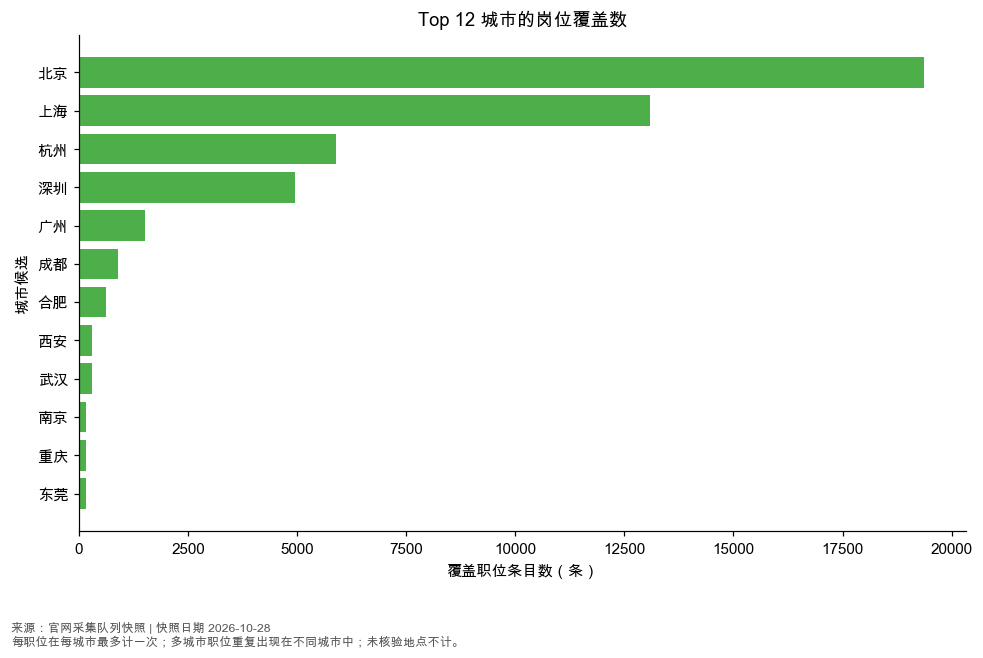

职位—城市关联总数： 50430
至少有一个城市候选的职位数： 39689
无城市候选的职位数： 972


,city,jobs,coverage_rate
39,北京,19363,0.476206
3,上海,13076,0.321586
147,杭州,5892,0.144905
184,深圳,4952,0.121787
105,广州,1510,0.037136
122,成都,886,0.021790
51,合肥,621,0.015273
237,西安,311,0.007649
155,武汉,298,0.007329
42,南京,173,0.004255


In [5]:
# 展开后同一职位可出现多行；需要保留job_key，后续才能回到不同职位数。
city_jobs = (jobs[['job_key', 'source', 'company_name', 'cities']].explode('cities')
             .dropna(subset=['cities']).rename(columns={'cities': 'city'}))
# 同一职位在同一城市最多计一次；跨城市的重复出现是统计设计，不是脏数据。
city_jobs = city_jobs.drop_duplicates(['job_key', 'city'])
city_counts = city_jobs.groupby('city', as_index=False).agg(jobs=('job_key', 'nunique')).sort_values('jobs', ascending=False)
# 这里用全量职位作分母，因此无城市候选的职位也留在分母中。
city_counts['coverage_rate'] = city_counts['jobs'] / N
top = city_counts.head(12).iloc[::-1]
# fig是整张图，ax是绘图区；figsize以英寸指定画布大小，后续save_figure统一添加来源注记。
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top['city'], top['jobs'], color='#4daf4a')
ax.set(title='Top 12 城市的岗位覆盖数', xlabel='覆盖职位条目数（条）', ylabel='城市候选')
save_figure(fig, '02_city_coverage', '每职位在每城市最多计一次；多城市职位重复出现在不同城市中；未核验地点不计。')
csv_export(city_counts, '02_city_counts')
print('职位—城市关联总数：', len(city_jobs))
print('至少有一个城市候选的职位数：', city_jobs.job_key.nunique())
print('无城市候选的职位数：', N - city_jobs.job_key.nunique())
display(city_counts.head(12))

## 4. 公司×城市热力图：同时看两种结构

热力图用公司全部职位数作分母，问“该公司样本中多少职位覆盖这个城市”。
一行可超过100%，因为职位支持多城市。只展示 Top 10 城市，其余仍保留在底稿。

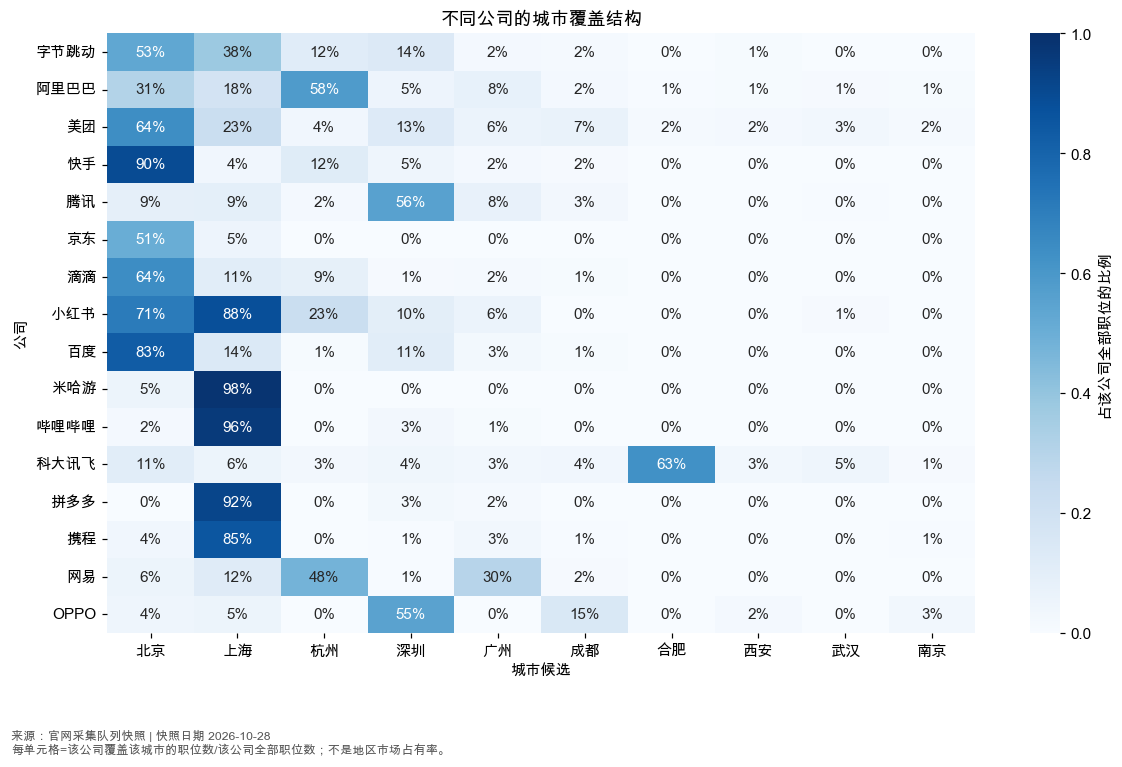

In [6]:
# 先得到公司×城市覆盖计数；这一层分母尚未统一，不能直接比较颜色深浅判断覆盖倾向。
cross_counts = pd.crosstab(city_jobs['company_name'], city_jobs['city'])
# 公司分母从一行一职位的主表计算，而非从已多城市展开的关联表计算。
denominators = jobs.groupby('company_name')['job_key'].nunique()
# 每一行除以对应公司的全部职位数；因为多城市覆盖，一行相加允许超过100%。
cross_rate = cross_counts.div(denominators, axis=0)
assert cross_rate.max().max() <= 1
fig, ax = plt.subplots(figsize=(11, 7))
# 按统一的公司/城市顺序排列；0只用于确定无关联的交叉项，不填补未知城市原值。
view = cross_rate.reindex(index=company_counts.company_name, columns=city_counts.city.head(10), fill_value=0)
sns.heatmap(view, ax=ax, annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=1,
            cbar_kws={'label': '占该公司全部职位的比例'})
ax.set(title='不同公司的城市覆盖结构', xlabel='城市候选', ylabel='公司')
save_figure(fig, '02_company_city', '每单元格=该公司覆盖该城市的职位数/该公司全部职位数；不是地区市场占有率。')
csv_export(cross_rate.reset_index(), '02_company_city_rate')

## 5. 分析前先看数据质量；可选检查日期

覆盖率图解释“能不能比较”。学历字段缺失不等于无学历要求，正文里可能另有说明。
发布日期可解析也不代表适合做趋势：历史保留、采集范围与下架机制都可能导致偏差。

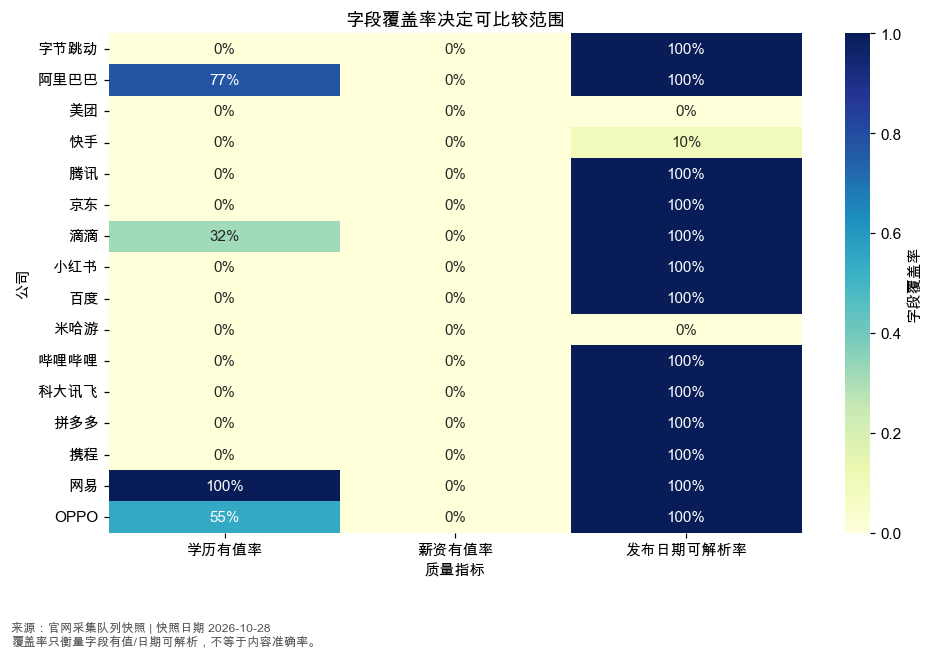

In [7]:
# 覆盖率描述“字段能否使用”，不描述“公司是否要求该条件”；原接口可能未提供字段。
coverage = jobs.groupby('company_name').agg(
    学历有值率=('required_degree', lambda s: s.fillna('').astype(str).str.strip().ne('').mean()),
    薪资有值率=('min_salary', lambda s: s.notna().mean()),
    发布日期可解析率=('publish_datetime', lambda s: s.notna().mean()),
)
# fig是整张图，ax是绘图区；figsize以英寸指定画布大小，后续save_figure统一添加来源注记。
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(coverage.reindex(company_counts.company_name), annot=True, fmt='.0%', vmin=0, vmax=1,
            cmap='YlGnBu', ax=ax, cbar_kws={'label': '字段覆盖率'})
ax.set(title='字段覆盖率决定可比较范围', xlabel='质量指标', ylabel='公司')
save_figure(fig, '02_field_coverage', '覆盖率只衡量字段有值/日期可解析，不等于内容准确率。')
csv_export(coverage.reset_index(), '02_field_coverage')
assert company_counts.jobs.sum() == N
# 每条去重城市关联恰好属于一个城市，因此各城市计数总和必须等于关联表长度。
assert city_counts.jobs.sum() == len(city_jobs)

## 5A. 【主线】结构集中度与累计贡献：不要预设“二八规律”成立

将公司按条数排序，累计占比回答“前几家公司覆盖了多少样本”。
HHI是各公司样本占比平方之和，越大代表来源越集中；这里衡量**数据来源结构**，不是市场垄断程度。
“前20%公司贡献80%职位”必须计算，不能看到头部较大就套用。

覆盖80%样本需要前7家公司；前20%公司向上取整为4家，贡献67.8%；HHI=0.211


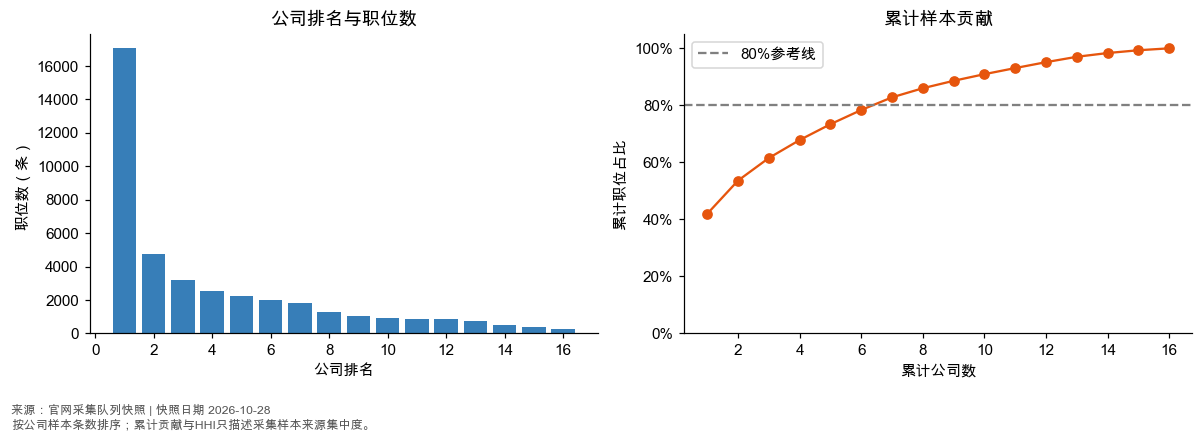

In [8]:
# 公司表已按条数降序；重新排连续索引后，排名与累计贡献才对应。
concentration = company_counts.copy().reset_index(drop=True)
concentration['rank'] = np.arange(1, len(concentration) + 1)
# cumsum逐行累计占比，不是假设每家公司均等贡献。
concentration['cumulative_share'] = concentration['share'].cumsum()
companies_to_80 = int(concentration.loc[concentration.cumulative_share.ge(.8), 'rank'].iloc[0])
# 平方会给大来源更高权重；此值衡量采集样本集中程度，不能套用市场监管阈值。
hhi = float((concentration['share'] ** 2).sum())
head_n = max(1, int(np.ceil(len(concentration) * .2)))
head_share = float(concentration.head(head_n)['share'].sum())
print(f'覆盖80%样本需要前{companies_to_80}家公司；前20%公司向上取整为{head_n}家，贡献{head_share:.1%}；HHI={hhi:.3f}')

# 用两个子图避免双Y轴让条数和比例难以分辨；条形图横轴从0开始。
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(concentration['rank'], concentration['jobs'], color='#377eb8')
axes[0].set(title='公司排名与职位数', xlabel='公司排名', ylabel='职位数（条）')
axes[1].plot(concentration['rank'], concentration['cumulative_share'], 'o-', color='#e6550d')
axes[1].axhline(.8, color='gray', linestyle='--', label='80%参考线')
axes[1].set(title='累计样本贡献', xlabel='累计公司数', ylabel='累计职位占比', ylim=(0, 1.05))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend()
save_figure(fig, '02_concentration', '按公司样本条数排序；累计贡献与HHI只描述采集样本来源集中度。')
csv_export(concentration, '02_concentration')

## 5B. 【主线】多城市的第二种口径：覆盖数与分摊数

假设某职位同时支持北京、上海：覆盖口径为两城各1条；平均分摊口径为两城各0.5条。
前者问“有多少职位允许在此地工作”，后者是**人为设定的折算方案**，不能解释为实际人员分配。
无城市候选的职位单独保留，这样可检查分摊质量是否守恒。

**练习**：如果一个职位支持50个城市，它在覆盖图与分摊图中的总贡献分别是多少？

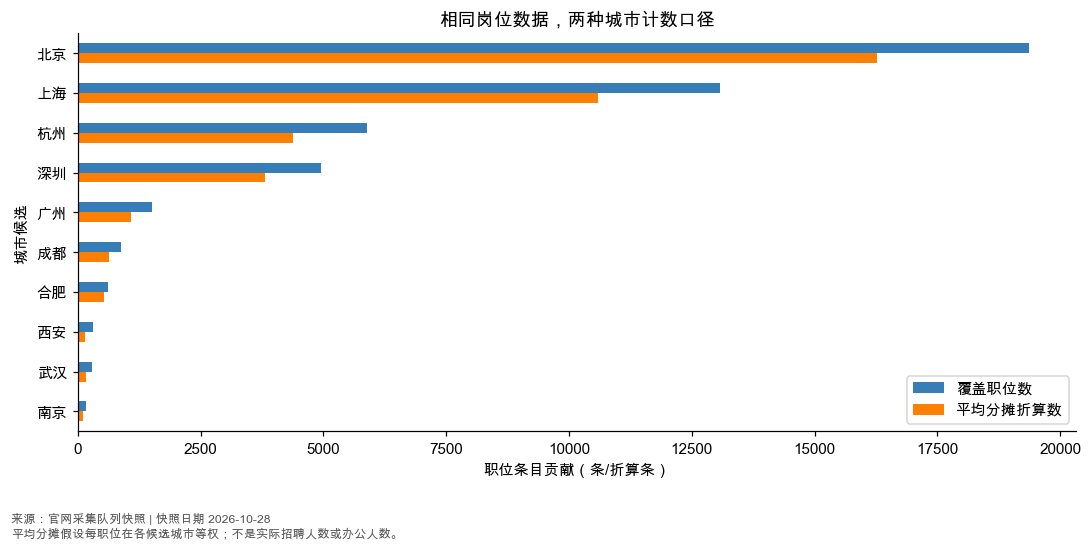

,city,jobs,coverage_rate,fractional_jobs
0,北京,19363,0.48,16277.74
1,上海,13076,0.32,10599.68
2,杭州,5892,0.14,4371.42
3,深圳,4952,0.12,3811.25
4,广州,1510,0.04,1078.46
5,成都,886,0.02,629.84
6,合肥,621,0.02,531.12
7,西安,311,0.01,150.56
8,武汉,298,0.01,170.31
9,南京,173,0.00,95.58


In [9]:
# 将每条城市关联补上该职位的城市数；关联基数必须是多对一。
weighted_links = city_jobs.merge(jobs[['job_key', 'city_count']], on='job_key', validate='many_to_one')
# 支持k个城市的职位给每城1/k权重；权重是分析者约定，不是观测到的招聘人数。
weighted_links['fractional_weight'] = 1 / weighted_links['city_count']
fractional = weighted_links.groupby('city', as_index=False).agg(fractional_jobs=('fractional_weight', 'sum'))
city_methods = city_counts.merge(fractional, on='city', validate='one_to_one')
missing_city_jobs = int(jobs['city_count'].eq(0).sum())
assert np.allclose(weighted_links.groupby('job_key')['fractional_weight'].sum(), 1)
assert np.isclose(fractional.fractional_jobs.sum() + missing_city_jobs, N)

# 两个系列都表示条目贡献，但一个计覆盖、一个计平均分摊，必须明确图例。
top_city_methods = city_methods.head(10).set_index('city')[['jobs', 'fractional_jobs']]
top_city_methods.columns = ['覆盖职位数', '平均分摊折算数']
fig, ax = plt.subplots(figsize=(10, 5))
top_city_methods.plot.barh(ax=ax, color=['#377eb8', '#ff7f00'])
ax.invert_yaxis()
ax.set(title='相同岗位数据，两种城市计数口径', xlabel='职位条目贡献（条/折算条）', ylabel='城市候选')
save_figure(fig, '02_city_counting_methods', '平均分摊假设每职位在各候选城市等权；不是实际招聘人数或办公人数。')
display(city_methods.head(10).round(2))
csv_export(city_methods, '02_city_counting_methods')

## 5C. 【拓展】比较前统一构成：招聘类型标准化

公司A与B的北京覆盖率可能不同，是因为岗位地点不同，也可能因为社招/校招比例不同。
这里仅比较社招和校招两类，要求每家公司每类至少30条，再把各公司内两类覆盖率按同一组权重加权。

公式：**标准化北京覆盖率 = 社招北京覆盖率×统一社招权重 + 校招北京覆盖率×统一校招权重**。
统一权重来自入选公司在这两类中的合并构成。没有这类样本的公司不填0，也不外推。
这是描述性构成调整，不是随机试验，无法消除岗位级别、业务线等其他混杂。

recruitment_type
society    0.726857
campus     0.273143
Name: 统一权重, dtype: float64

,raw_rate,standardized_rate,n,change_pp
company_name,,,,
美团,0.637,0.661,3221,2.372
小红书,0.777,0.790,1022,1.355
米哈游,0.046,0.054,805,0.848
滴滴,0.678,0.683,1193,0.440
快手,0.894,0.897,1421,0.366
拼多多,0.000,0.000,767,0.000
哔哩哔哩,0.027,0.026,562,-0.058
科大讯飞,0.113,0.111,841,-0.197
携程,0.037,0.034,534,-0.362


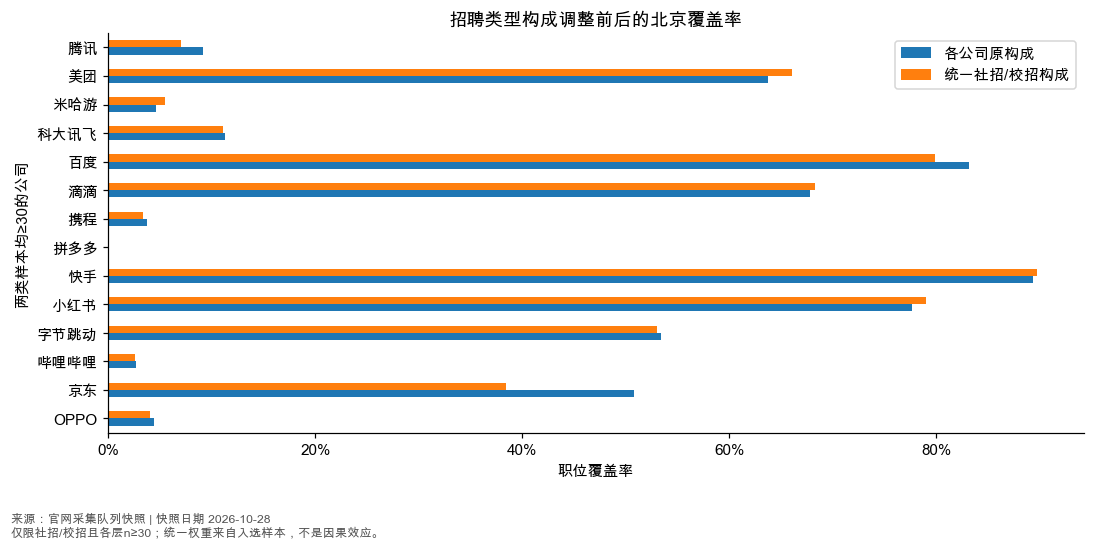

In [10]:
comparison_jobs = jobs.loc[jobs['recruitment_type'].isin(['society', 'campus'])].copy()
comparison_jobs['covers_beijing'] = comparison_jobs['cities'].map(lambda xs: '北京' in xs)
stratum_counts = pd.crosstab(comparison_jobs.company_name, comparison_jobs.recruitment_type)
qualified = stratum_counts.reindex(columns=['society', 'campus'], fill_value=0).ge(30).all(axis=1)
qualified_names = qualified.index[qualified]
comparison_jobs = comparison_jobs.loc[comparison_jobs.company_name.isin(qualified_names)]
assert len(qualified_names) >= 2, '可比公司过少，应调整研究范围，不能硬填缺失层'

# 同一组权重给每家公司使用，消除这一项招聘类型构成差异。
common_weights = comparison_jobs.recruitment_type.value_counts(normalize=True).reindex(['society', 'campus'])
within_rates = comparison_jobs.groupby(['company_name', 'recruitment_type']).covers_beijing.mean().unstack()
# 按招聘类型列乘同一权重后加总；每家公司的结果使用相同构成，才具有这一限定意义的可比性。
standardized = within_rates.mul(common_weights, axis=1).sum(axis=1)
adjustment = pd.DataFrame({'raw_rate': comparison_jobs.groupby('company_name').covers_beijing.mean(),
                           'standardized_rate': standardized,
                           'n': comparison_jobs.groupby('company_name').size()})
adjustment['change_pp'] = (adjustment.standardized_rate - adjustment.raw_rate) * 100
display(common_weights.rename('统一权重'))
display(adjustment.sort_values('change_pp', ascending=False).round(3))
assert np.isclose(common_weights.sum(), 1)
assert adjustment[['raw_rate', 'standardized_rate']].stack().between(0, 1).all()
fig, ax = plt.subplots(figsize=(10, 5))
adjustment[['raw_rate', 'standardized_rate']].rename(columns={
    'raw_rate': '各公司原构成', 'standardized_rate': '统一社招/校招构成'}).plot.barh(ax=ax)
# 数据本身是0到1的小数，PercentFormatter(1)只把坐标标签显示成百分比。
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(title='招聘类型构成调整前后的北京覆盖率', xlabel='职位覆盖率', ylabel='两类样本均≥30的公司')
save_figure(fig, '02_standardized_beijing', '仅限社招/校招且各层n≥30；统一权重来自入选样本，不是因果效应。')
csv_export(adjustment.reset_index(), '02_standardized_beijing')

In [11]:
write_json(REPORTS / 'structure_extension_metrics.json', {
    'companies_to_80pct': companies_to_80, 'top_20pct_company_n': head_n,
    'top_20pct_company_share': head_share, 'source_hhi': hhi,
    'fractional_city_total': float(fractional.fractional_jobs.sum()), 'no_city_jobs': missing_city_jobs,
    'standardization_companies': len(qualified_names), 'standardization_weights': common_weights.to_dict(),
})

## 5D. 【练习与参考】下钻，而不是追加一张排行榜

任务：只看北京可工作的社招职位，比较其公司结构与全量样本公司结构。
答案应同时包括子集条数、子集内占比、相对全量的百分点差，避免拿两个分母不同的数量直接相减。

In [12]:
# 列表包含检查仍在一行一职位的主表上做，避免explode后反复统计。
drill_mask = jobs['recruitment_type'].eq('society') & jobs['cities'].map(lambda xs: '北京' in xs)
drill_jobs = jobs.loc[drill_mask]
drill_counts = drill_jobs.groupby('company_name').size().rename('subset_jobs')
drill = company_counts.set_index('company_name')[['jobs', 'share']].join(drill_counts).fillna({'subset_jobs': 0})
drill['subset_share'] = drill['subset_jobs'] / len(drill_jobs)
# 两个比例相减后乘100，单位是百分点；不能把百分点差写成相对增长百分比。
drill['share_change_pp'] = (drill['subset_share'] - drill['share']) * 100
assert np.isclose(drill.subset_share.sum(), 1)
print('北京可工作的社招子集：', len(drill_jobs), '条')
display(drill.sort_values('subset_jobs', ascending=False).round(3))
csv_export(drill.reset_index(), '02_beijing_society_drilldown')

北京可工作的社招子集： 12311 条


,jobs,share,subset_jobs,subset_share,share_change_pp
company_name,,,,,
字节跳动,17053,0.419,5219.0,0.424,0.454
美团,3221,0.079,1579.0,0.128,4.904
快手,2563,0.063,1029.0,0.084,2.055
京东,2025,0.050,1028.0,0.084,3.370
阿里巴巴,4744,0.117,922.0,0.075,-4.178
百度,1058,0.026,784.0,0.064,3.766
滴滴,1808,0.044,744.0,0.060,1.597
小红书,1299,0.032,655.0,0.053,2.126
腾讯,2259,0.056,207.0,0.017,-3.874


## 6. 从图表写出有依据的结论

下面的文字由实际底稿生成，不预先写死数值。每条结论都带范围与限制。
因果归因需要额外证据，本课只能描述关联和样本结构。

In [13]:
first = company_counts.iloc[0]
city_first = city_counts.iloc[0]
# 结论所用数值从同一张底稿提取，避免文字中的数字与图表各算一遍产生差异。
facts = {
    'jobs': N, 'companies': int(jobs.source.nunique()),
    'top_company': first.company_name, 'top_company_jobs': int(first.jobs), 'top_company_share': float(first.share),
    'top_city': city_first.city, 'top_city_jobs': int(city_first.jobs),
    'top_city_coverage': float(city_first.coverage_rate),
    'city_associations': len(city_jobs), 'jobs_with_city': int(city_jobs.job_key.nunique()),
}
write_json(REPORTS / 'structure_metrics.json', facts)
display(Markdown(f"""**现象**：样本中{first.company_name}职位最多，共 {first.jobs:,} 条，占 {first.share:.1%}。

**解读边界**：样本受到采集覆盖及历史保留影响，不能据此认定该公司实际招聘需求最大。

**现象**：{city_first.city}覆盖 {city_first.jobs:,} 条职位，占全部职位 {city_first.coverage_rate:.1%}。

**解读边界**：这是多城市岗位覆盖率，非互斥城市份额。"""))

**现象**：样本中字节跳动职位最多，共 17,053 条，占 41.9%。

**解读边界**：样本受到采集覆盖及历史保留影响，不能据此认定该公司实际招聘需求最大。

**现象**：北京覆盖 19,363 条职位，占全部职位 47.6%。

**解读边界**：这是多城市岗位覆盖率，非互斥城市份额。

## 练习（含参考方向）

1. 仅选择“社招”重做公司数量图，比较排序是否变化。（先过滤再聚合，分母也要改变。）
2. 为什么城市覆盖率不能直接用饼图？（类别不互斥。）
3. 选择一家小样本公司与一家大样本公司，分别比较数量和公司内占比。
4. 某公司学历覆盖率为0，能否说它不要求学历？（不能，下一课回到文本核验。）

**验收**：公司计数之和=职位数；公司内类型占比合计100%；城市底稿与展开关联数一致。
输出：5 张 PNG、对应 CSV 底稿、`structure_metrics.json`。